# Assignment 3

Border and complement, on a grayscale image and on a binary image.

Sample: `sample_portrait.jpg`. A black border and the negative of a face are easy to see. Border width is 20 pixels and the border colour is 0.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# border around the image, and the complement
# tried on a grayscale image and on a binary image

def add_border(img, width, color):
    return cv2.copyMakeBorder(
        img, width, width, width, width, cv2.BORDER_CONSTANT, value=int(color)
    )


def complement(img):
    # s = 255 - r   (for binary this just flips 0 and 255)
    return (255 - img).astype(np.uint8)


def make_binary(img):
    t = float(img.mean())
    out = np.zeros_like(img)
    out[img >= t] = 255
    return out, t


sample image: sample_portrait.jpg (256, 256)
binary image made with mean threshold = 135.1
grayscale border colour = 0
binary border colour set to 0 , width = 20


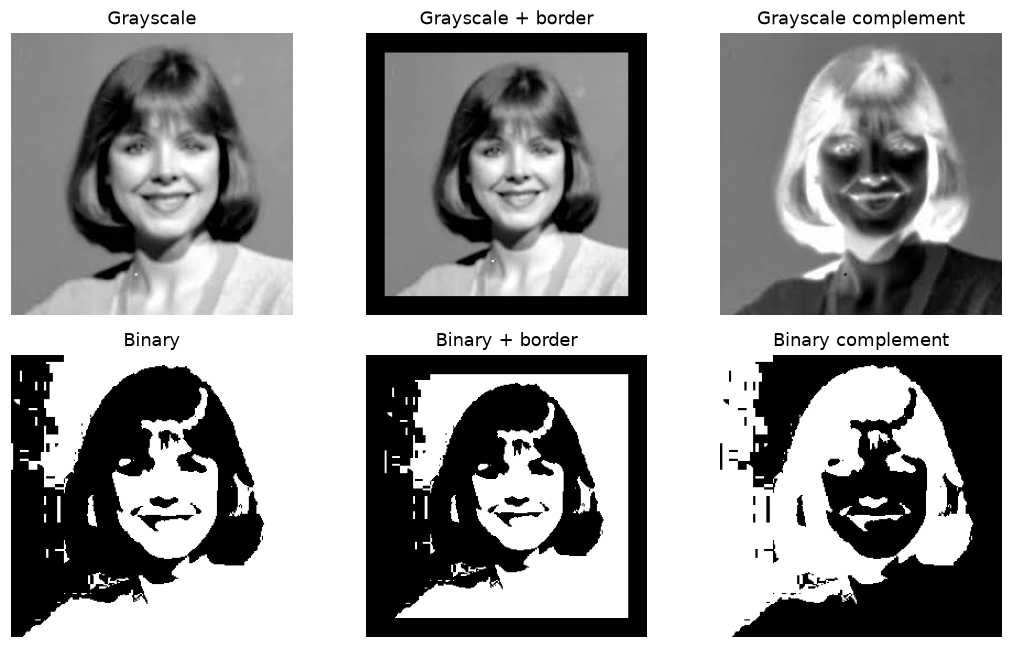

In [2]:
image_path = "sample_portrait.jpg"
width = 20
color = 0

gray = cv2.imread(image_path, 0)
print("sample image:", image_path, gray.shape)

binary, t = make_binary(gray)
print("binary image made with mean threshold =", round(t, 2))

bin_color = 255 if color >= 128 else 0
print("grayscale border colour =", color)
print("binary border colour set to", bin_color, ", width =", width)

gray_pad = add_border(gray, width, color)
bin_pad = add_border(binary, width, bin_color)
gray_comp = complement(gray)
bin_comp = complement(binary)

plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(gray_pad, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale + border")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(gray_comp, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale complement")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(bin_pad, cmap="gray", vmin=0, vmax=255)
plt.title("Binary + border")
plt.axis("off")
plt.subplot(2, 3, 6)
plt.imshow(bin_comp, cmap="gray", vmin=0, vmax=255)
plt.title("Binary complement")
plt.axis("off")
plt.tight_layout()
plt.show()
